# MBA · Machine Learning e Hiperpersonalização
## Atividade 2 — Prever o churn dos alunos atuais da EnglishPro
**Aula de 28 de outubro de 2026 · Vibe Coding Executivo**

Este notebook aplica o modelo vencedor da Atividade 1 aos alunos atuais. **Não há treinamento nem chamada a `fit`.** O objetivo é gerar uma previsão de cancelamento nos próximos 60 dias, um Excel de importação e um resumo para a gestão.

**Execução local no VS Code:** selecione como kernel o Python em `../atividade-1-notebook/.venv/bin/python` e clique em **Executar tudo**. O notebook já contém as saídas desta execução. O ambiente e as versões da Atividade 1 são reutilizados, sem nova instalação.

O Excel terá uma única aba e exatamente duas colunas: `id_aluno`, `probabilidade_churn`. As probabilidades serão números de 0 a 100 com uma casa decimal (37.5 = 37,5%). Os arquivos originais e o modelo serão preservados.

**Ingestão:** enunciado transcrito em `enunciado-atividade-2.txt`; base `Atividade 2 - EnglishPro_Dados_Alunos_Prontos_ML.xlsx`, aba `Dados_Alunos`. A pasta original `Aula 04 - Atividades ` tem um espaço no final do nome. A importação no Lovable pertence à Atividade 3.

### 1. Localizar as entradas e carregar o ambiente
Os caminhos são descobertos a partir desta pasta. Para outras pastas, preencha os caminhos opcionais abaixo. O exportador Excel usa Node.js e o pacote `@oai/artifact-tool` disponibilizado pelo Codex neste computador. Para outro computador, informe `NODE_BIN` e `ARTIFACT_NODE_MODULES`, conforme `LEIA-ME.txt`.

In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib, json, os, shutil, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from openpyxl import load_workbook  # somente leitura para conferir o Excel exportado
from IPython.display import display, Markdown

ARQUIVO_ALUNOS = None  # opcional: caminho completo da planilha atual
ARQUIVO_MODELO = None  # opcional: caminho completo de modelo_churn.joblib
ARQUIVO_HISTORICO = None  # opcional: planilha de treino, usada apenas para comparação
PASTA = Path.cwd()
if PASTA.name != 'atividade-2-notebook' and (PASTA/'atividade-2-notebook').is_dir():
    PASTA = PASTA/'atividade-2-notebook'
RAIZ_AULA = PASTA.parent
SAIDA = PASTA/'resultados'
SAIDA.mkdir(exist_ok=True)
def encontrar(padrao):
    encontrados = sorted(RAIZ_AULA.glob('Aula 04 - Atividades*/' + padrao))
    if len(encontrados) != 1:
        raise FileNotFoundError(f'Informe o caminho explicitamente para {padrao}; encontrados: {encontrados}')
    return encontrados[0]
arquivo = Path(ARQUIVO_ALUNOS).expanduser() if ARQUIVO_ALUNOS else encontrar('Atividade 2*.xlsx')
caminho_modelo = Path(ARQUIVO_MODELO).expanduser() if ARQUIVO_MODELO else RAIZ_AULA/'atividade-1-notebook/resultados/modelo_churn.joblib'
arquivo_historico = Path(ARQUIVO_HISTORICO).expanduser() if ARQUIVO_HISTORICO else encontrar('Atividade 1*.xlsx')
def sha256(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
hash_modelo_antes = sha256(caminho_modelo)
hash_alunos = sha256(arquivo)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
print('Base atual:', arquivo.name)
print('Modelo:', caminho_modelo)
print('SHA-256 do modelo:', hash_modelo_antes)

Base atual: Atividade 2 - EnglishPro_Dados_Alunos_Prontos_ML.xlsx
Modelo: /Users/afigueiredo/Documents/ChatGPT/mba-ai-leadership-4abl/disciplinas/21-vibe-coding-executivo/aulas/Aula-04/atividade-1-notebook/resultados/modelo_churn.joblib
SHA-256 do modelo: 103a090535450b336cd615643e2d3e1239b75c464742242f438beca60d276245


### 2. Reutilizar exatamente o modelo da Atividade 1
Carregamos o pipeline Random Forest já ajustado. O identificador não entra na previsão. As cinco características são selecionadas na ordem registrada no artefato. A verificação de versões evita previsões produzidas por um ambiente incompatível. Carregue arquivos `joblib` somente de origem conhecida.

In [2]:
artefato = joblib.load(caminho_modelo)
for pacote, esperada in artefato['versoes'].items():
    assert version(pacote) == esperada, f'{pacote}: esperado {esperada}, encontrado {version(pacote)}. Use o ambiente da Atividade 1.'
modelo = artefato['modelo']
FEATURES = artefato['features']
assert len(FEATURES) == 5 and 'id_aluno' not in FEATURES and artefato['alvo'] not in FEATURES
assert list(modelo.feature_names_in_) == FEATURES
assert list(modelo.classes_) == [0, 1]
historico = pd.read_excel(arquivo_historico, sheet_name='base_treinamento')
assert sha256(arquivo_historico) == artefato['hash_fonte'], 'A base histórica diverge da usada no treinamento.'
print('Modelo carregado:', artefato['vencedor'])
print('Entradas:', FEATURES)
print('Nenhum ajuste ou re-treinamento será feito.')

Modelo carregado: Random forest
Entradas: ['tempo_casa_meses', 'taxa_inadimplencia_historica', 'n_parcelas_atrasadas_90_dias', 'taxa_presenca_30_dias', 'n_acessos_plataforma_30_dias']
Nenhum ajuste ou re-treinamento será feito.


### 3. Validar os alunos atuais
Conferimos IDs inteiros, positivos e únicos, cinco entradas numéricas, ausência de valores nulos/infinitos, proporções entre 0 e 1 e contagens não negativas. Também comparamos limites observados com o histórico; valores novos são sinalizados sem excluir alunos automaticamente.

Os identificadores são usados apenas para devolver o resultado a cada linha da base atual. A numeração coincidente entre planilhas não comprova que se trata das mesmas pessoas; não fazemos junção dos rótulos históricos com os alunos atuais.

In [3]:
alunos = pd.read_excel(arquivo, sheet_name='Dados_Alunos')
assert set(alunos.columns) == set(['id_aluno', *FEATURES]), 'Esquema inesperado'
assert not alunos.empty and not alunos.isna().any().any(), 'Dados vazios ou ausentes'
assert alunos.id_aluno.is_unique, 'IDs duplicados'
for c in alunos.columns:
    assert pd.api.types.is_numeric_dtype(alunos[c]) and np.isfinite(alunos[c]).all(), f'Valores inválidos: {c}'
assert (alunos.id_aluno > 0).all() and (alunos.id_aluno % 1 == 0).all()
for c in ['tempo_casa_meses', 'n_parcelas_atrasadas_90_dias', 'n_acessos_plataforma_30_dias']:
    assert (alunos[c] >= 0).all() and (alunos[c] % 1 == 0).all(), f'Contagem inválida: {c}'
for c in ['taxa_inadimplencia_historica', 'taxa_presenca_30_dias']:
    assert alunos[c].between(0, 1).all(), f'Taxa fora da escala: {c}'
limites = pd.DataFrame({'mínimo_histórico': historico[FEATURES].min(), 'máximo_histórico': historico[FEATURES].max(),
                       'mínimo_atual': alunos[FEATURES].min(), 'máximo_atual': alunos[FEATURES].max()})
limites['alunos_fora_limites_históricos'] = [int((~alunos[c].between(historico[c].min(), historico[c].max())).sum()) for c in FEATURES]
display(limites)
limites.to_csv(SAIDA/'comparacao_limites.csv')
print(f'{len(alunos):,} alunos validados; nenhum ID duplicado ou valor ausente.')
display(alunos.head())

,mínimo_histórico,máximo_histórico,mínimo_atual,máximo_atual,alunos_fora_limites_históricos
tempo_casa_meses,1.0,68.000,1.0,68.000,0
taxa_inadimplencia_historica,0.0,0.700,0.0,0.700,0
n_parcelas_atrasadas_90_dias,0.0,3.000,0.0,3.000,0
taxa_presenca_30_dias,0.0,0.998,0.0,0.998,0
n_acessos_plataforma_30_dias,0.0,54.000,0.0,57.000,1


13,000 alunos validados; nenhum ID duplicado ou valor ausente.


,id_aluno,tempo_casa_meses,taxa_inadimplencia_historica,n_parcelas_atrasadas_90_dias,taxa_presenca_30_dias,n_acessos_plataforma_30_dias
0,1,2,0.000,0,0.762,38
1,2,2,0.000,0,0.784,23
2,3,4,0.051,0,0.806,33
3,4,40,0.339,3,0.930,34
4,5,5,0.000,0,0.861,33


### 4. Calcular a probabilidade de cancelamento
`predict_proba` usa o modelo carregado para estimar o risco, sem aprender com esta base. Mantemos a ordem original dos alunos. Guardamos a probabilidade completa para rastreabilidade; o Excel usa escala de 0 a 100 arredondada para uma casa decimal.

Probabilidades 0,0 ou 100,0 após arredondamento não significam certeza. Não existe rótulo de cancelamento nesta base, portanto não é possível calcular AUC, acurácia ou cancelamentos efetivos dos alunos atuais.

In [4]:
p = modelo.predict_proba(alunos[FEATURES])[:, 1]
assert len(p) == len(alunos) and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
previsao = pd.DataFrame({'id_aluno': alunos.id_aluno.astype('int64'),
                       'probabilidade_churn': np.round(p * 100, 1)})
assert previsao.columns.tolist() == ['id_aluno', 'probabilidade_churn']
assert previsao.id_aluno.tolist() == alunos.id_aluno.tolist()
assert previsao.probabilidade_churn.between(0,100).all()
auditoria = alunos.copy()
auditoria['probabilidade_0_a_1'] = p
auditoria['probabilidade_churn'] = previsao.probabilidade_churn
auditoria.to_csv(SAIDA/'previsoes_detalhadas.csv', index=False)
print(f'Previsão calculada para {len(previsao):,} alunos; modelo preservado.')
display(previsao.head(10))

Previsão calculada para 13,000 alunos; modelo preservado.


,id_aluno,probabilidade_churn
0,1,1.1
1,2,3.2
2,3,1.4
3,4,12.5
4,5,0.6
5,6,0.2
6,7,13.0
7,8,25.9
8,9,20.9
9,10,2.8


### 5. Distribuição nas cinco faixas pedidas no enunciado
As faixas usam **o número arredondado que será importado no aplicativo**: `[0,20)`, `[20,40)`, `[40,60)`, `[60,80)` e `[80,100]`. Um aluno com exatamente 20 entra na segunda faixa; 100 entra na última. A contagem cobre todos os alunos uma única vez.

,faixa_churn_pct,alunos,percentual_da_base
0,0–20,8663,66.64
1,20–40,1925,14.81
2,40–60,972,7.48
3,60–80,888,6.83
4,80–100,552,4.25


Checagem dos extremos: {'abaixo_1_pct': 1795, 'acima_90_pct': 216}


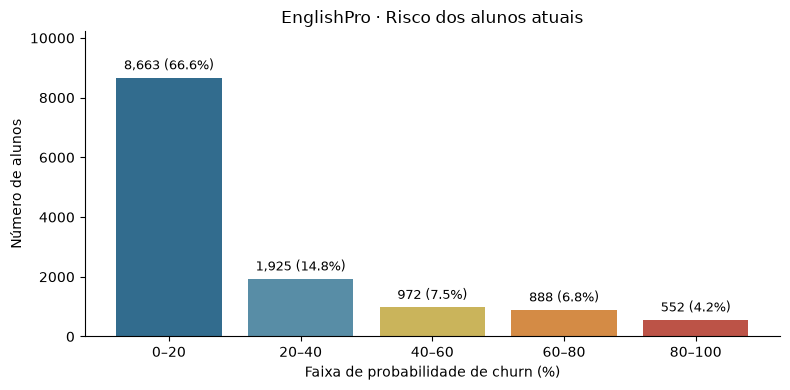

In [5]:
ROTULOS = ['0–20', '20–40', '40–60', '60–80', '80–100']
def indice_faixa(v): return np.minimum(np.floor(np.asarray(v)/20).astype(int), 4)
assert indice_faixa([0,19.9,20,39.9,40,59.9,60,79.9,80,100]).tolist() == [0,0,1,1,2,2,3,3,4,4]
indices = indice_faixa(previsao.probabilidade_churn)
contagens = np.bincount(indices, minlength=5)
faixas = pd.DataFrame({'faixa_churn_pct':ROTULOS, 'alunos':contagens,
                      'percentual_da_base':np.round(contagens/len(previsao)*100,2)})
assert int(faixas.alunos.sum()) == len(previsao)
display(faixas)
faixas.to_csv(SAIDA/'distribuicao_faixas.csv', index=False)
extremos = {'abaixo_1_pct':int((previsao.probabilidade_churn < 1).sum()),
            'acima_90_pct':int((previsao.probabilidade_churn > 90).sum())}
print('Checagem dos extremos:', extremos)
fig, ax = plt.subplots(figsize=(8,4))
bars = ax.bar(ROTULOS,contagens,color=['#326c8e','#588da6','#cab45b','#d48b45','#bc5347'])
ax.bar_label(bars, labels=[f'{v:,} ({v/len(previsao):.1%})' for v in contagens], padding=4, fontsize=9)
ax.set(xlabel='Faixa de probabilidade de churn (%)', ylabel='Número de alunos',title='EnglishPro · Risco dos alunos atuais')
ax.set_ylim(0,max(contagens)*1.18)
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(SAIDA/'distribuicao_risco.png',dpi=150); plt.show()

### 6. Os dez alunos de maior risco e sua coerência com a Atividade 1
A ordenação considera a probabilidade completa antes do arredondamento; empates são resolvidos por ID crescente. O Excel preservará a ordem original. Comparamos as características do grupo de dez com a média dos alunos atuais e a importância calculada na Atividade 1.

In [6]:
top10 = auditoria.sort_values(['probabilidade_0_a_1','id_aluno'], ascending=[False,True]).head(10).copy()
display(top10[['id_aluno','probabilidade_churn',*FEATURES]])
top10[['id_aluno','probabilidade_churn',*FEATURES]].to_csv(SAIDA/'top10_maior_risco.csv',index=False)
comparacao = pd.DataFrame({'media_base_atual':alunos[FEATURES].mean(), 'media_top10':top10[FEATURES].mean()})
comparacao['diferença'] = comparacao.media_top10 - comparacao.media_base_atual
display(comparacao.round(4))
comparacao.to_csv(SAIDA/'comparacao_top10.csv')
arq_importancia = RAIZ_AULA/'atividade-1-notebook/resultados/importancia_variaveis.csv'
if arq_importancia.exists():
    display(pd.read_csv(arq_importancia)[['feature','queda_auc_media','direcao_no_contraste']])
observacoes = []
for c, linha in comparacao.iterrows():
    sentido = 'menor' if linha['diferença'] < 0 else 'maior' if linha['diferença'] > 0 else 'igual'
    observacoes.append(f'{c}: média {linha.media_top10:.3f} nos dez de maior risco, {sentido} que a média atual {linha.media_base_atual:.3f}.')
print('\n'.join(observacoes))
print('Compare menor presença/engajamento e maiores atrasos com as associações da Atividade 1. Isso verifica coerência, sem demonstrar causa nem efeito de um desconto.')

,id_aluno,probabilidade_churn,tempo_casa_meses,taxa_inadimplencia_historica,n_parcelas_atrasadas_90_dias,taxa_presenca_30_dias,n_acessos_plataforma_30_dias
8686,8687,98.9,5,0.332,2,0.054,0
6012,6013,98.9,3,0.328,2,0.047,0
8031,8032,98.6,6,0.298,3,0.067,1
12840,12841,98.5,7,0.331,3,0.249,4
3075,3076,98.5,1,0.340,3,0.087,0
1405,1406,98.5,5,0.318,2,0.267,10
8583,8584,98.3,2,0.271,2,0.053,0
7074,7075,98.3,3,0.357,2,0.349,4
9765,9766,98.2,2,0.318,3,0.375,5
5340,5341,98.2,5,0.338,3,0.214,0


,media_base_atual,media_top10,diferença
tempo_casa_meses,13.3407,3.9000,-9.4407
taxa_inadimplencia_historica,0.1080,0.3231,0.2151
n_parcelas_atrasadas_90_dias,0.5243,2.5000,1.9757
taxa_presenca_30_dias,0.6253,0.1762,-0.4491
n_acessos_plataforma_30_dias,22.5125,2.4000,-20.1125


,feature,queda_auc_media,direcao_no_contraste
0,taxa_presenca_30_dias,0.094148,reduz
1,n_parcelas_atrasadas_90_dias,0.060792,aumenta
2,taxa_inadimplencia_historica,0.052048,aumenta
3,tempo_casa_meses,0.032577,reduz
4,n_acessos_plataforma_30_dias,0.030124,reduz


tempo_casa_meses: média 3.900 nos dez de maior risco, menor que a média atual 13.341.
taxa_inadimplencia_historica: média 0.323 nos dez de maior risco, maior que a média atual 0.108.
n_parcelas_atrasadas_90_dias: média 2.500 nos dez de maior risco, maior que a média atual 0.524.
taxa_presenca_30_dias: média 0.176 nos dez de maior risco, menor que a média atual 0.625.
n_acessos_plataforma_30_dias: média 2.400 nos dez de maior risco, menor que a média atual 22.512.
Compare menor presença/engajamento e maiores atrasos com as associações da Atividade 1. Isso verifica coerência, sem demonstrar causa nem efeito de um desconto.


### 7. Gerar o Excel para a próxima atividade
O exportador grava valores numéricos, sem fórmulas, cabeçalho na primeira linha e uma única aba. A coluna de risco usa o formato `0.0`, e não o formato percentual do Excel: o valor armazenado 37.5 já representa 37,5%. As explicações e campos auxiliares ficam fora da planilha para cumprir o formato de importação.

In [7]:
json_exportacao = SAIDA/'dados_exportacao.json'
registros = [[int(i),float(v)] for i,v in previsao.itertuples(index=False,name=None)]
json_exportacao.write_text(json.dumps(registros),encoding='utf-8')
node_padrao = Path.home()/'.cache/codex-runtimes/codex-primary-runtime/dependencies/node/bin/node'
node = os.environ.get('NODE_BIN') or (str(node_padrao) if node_padrao.exists() else shutil.which('node'))
if not node:
    raise RuntimeError('Node.js não encontrado. Configure NODE_BIN e consulte LEIA-ME.txt.')
excel = SAIDA/'EnglishPro_Previsao_Churn.xlsx'
processo = subprocess.run([node,str(PASTA/'exportar_previsao.mjs'),str(json_exportacao),str(excel),str(SAIDA/'previa_excel.png')],
                         text=True,capture_output=True)
if processo.returncode:
    raise RuntimeError(processo.stderr or processo.stdout)
print(processo.stdout)

{"kind":"table","sheet":"Previsao_Churn","address":"A1:B6","rows":6,"cols":2,"values":[["id_aluno","probabilidade_churn"],[1,1.1],[2,3.2],[3,1.4],[4,12.5],[5,0.6]]}
Inspect result written to file: /Users/afigueiredo/Documents/ChatGPT/mba-ai-leadership-4abl/disciplinas/21-vibe-coding-executivo/aulas/Aula-04/atividade-2-notebook/resultados/EnglishPro_Previsao_Churn.xlsx.inspect.ndjson
Excel gerado: 13000 alunos, duas colunas numéricas.



### 8. Reabrir e conferir a entrega
Verificamos todas as 13.000 linhas exportadas contra as previsões, tipos numéricos, ordem dos IDs, precisão, ausência de fórmulas, linhas vazias ou colunas extras. O hash do arquivo do modelo deve permanecer idêntico ao inicial.

In [8]:
wb = load_workbook(excel, data_only=False, read_only=False)
assert wb.sheetnames == ['Previsao_Churn']
ws = wb.active
assert ws.max_column == 2 and ws.max_row == len(previsao)+1
linhas = list(ws.iter_rows())
assert [c.value for c in linhas[0]] == ['id_aluno','probabilidade_churn']
for celulas, esperado in zip(linhas[1:],registros):
    assert all(c.data_type == 'n' and c.value is not None for c in celulas)
    assert celulas[0].value == esperado[0]
    assert abs(celulas[1].value-esperado[1]) < 1e-10
    assert 0 <= celulas[1].value <= 100
    assert celulas[1].number_format == '0.0'
wb.close()
assert sha256(caminho_modelo) == hash_modelo_antes, 'O modelo foi alterado'
assert sha256(arquivo) == hash_alunos, 'A fonte foi alterada'
resumo = {'aula':'2026-10-28','execucao':datetime.now(ZoneInfo('America/Sao_Paulo')).isoformat(),
    'modelo':artefato['vencedor'],'retreinado':False,'sha256_modelo':hash_modelo_antes,
    'fonte':arquivo.name,'sha256_fonte':hash_alunos,'alunos':len(previsao),
    'probabilidade_min_pct':float(previsao.probabilidade_churn.min()),
    'probabilidade_max_pct':float(previsao.probabilidade_churn.max()),
    'faixas':faixas.to_dict(orient='records'),'regra_faixas':'[0,20), [20,40), [40,60), [60,80), [80,100], sobre valores arredondados',
    'extremos':extremos,'top10':top10[['id_aluno','probabilidade_churn']].to_dict(orient='records'),
    'sha256_excel':sha256(excel),'verificacoes':'todas as linhas, tipos, precisão, ordem, esquema e hashes conferidos',
    'versoes':artefato['versoes']}
(SAIDA/'resumo_execucao.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2),encoding='utf-8')
texto = ['EnglishPro — Atividade 2 — Aula de 28/10/2026',
    f'Modelo: {artefato["vencedor"]}, carregado da Atividade 1 sem re-treinamento.',
    f'{len(previsao)} alunos processados. IDs únicos, dados completos e arquivo exportado conferido.',
    f'Risco mínimo: {previsao.probabilidade_churn.min():.1f}%; máximo: {previsao.probabilidade_churn.max():.1f}%.',
    '\nDistribuição por faixa (inclui o limite inferior e exclui o superior, exceto 100):']
for linha in faixas.itertuples(index=False):
    texto.append(f'{linha.faixa_churn_pct}%: {linha.alunos} alunos ({linha.percentual_da_base:.2f}% da base).')
texto += ['\nDez maiores riscos:']
for linha in top10.itertuples(index=False):
    texto.append(f'Aluno {linha.id_aluno}: {linha.probabilidade_churn:.1f}%.')
texto += ['\nCaracterísticas do grupo de maior risco:',*observacoes,
    '\nConclusão para a gestão: priorize a análise dos alunos de maior risco; presença e atrasos ajudam a direcionar a conversa. Risco não mede resposta a desconto. As campanhas dependem de decisão de negócio e validação por experimento.',
    'Não há rótulos atuais para medir AUC ou cancelamento efetivo. Não se deve ajustar a distribuição para forçar as expectativas do roteiro.',
    f'Extremos: {extremos["abaixo_1_pct"]} alunos abaixo de 1%; {extremos["acima_90_pct"]} acima de 90%.',
    'Valores arredondados de 0,0% ou 100,0% não representam certeza.',
    'A importação e as campanhas no Lovable (Atividade 3) não foram executadas.',
    f'Arquivo de importação: {excel.name}. Uma aba, duas colunas, números e uma casa decimal.',
    f'SHA-256 do modelo preservado: {hash_modelo_antes}']
conclusao = '\n'.join(texto)
(SAIDA/'conclusao_atividade_2.txt').write_text(conclusao,encoding='utf-8')
print(conclusao)
print('\nValidação concluída: todas as linhas conferidas; fontes e modelo preservados.')

EnglishPro — Atividade 2 — Aula de 28/10/2026
Modelo: Random forest, carregado da Atividade 1 sem re-treinamento.
13000 alunos processados. IDs únicos, dados completos e arquivo exportado conferido.
Risco mínimo: 0.0%; máximo: 98.9%.

Distribuição por faixa (inclui o limite inferior e exclui o superior, exceto 100):
0–20%: 8663 alunos (66.64% da base).
20–40%: 1925 alunos (14.81% da base).
40–60%: 972 alunos (7.48% da base).
60–80%: 888 alunos (6.83% da base).
80–100%: 552 alunos (4.25% da base).

Dez maiores riscos:
Aluno 8687: 98.9%.
Aluno 6013: 98.9%.
Aluno 8032: 98.6%.
Aluno 12841: 98.5%.
Aluno 3076: 98.5%.
Aluno 1406: 98.5%.
Aluno 8584: 98.3%.
Aluno 7075: 98.3%.
Aluno 9766: 98.2%.
Aluno 5341: 98.2%.

Características do grupo de maior risco:
tempo_casa_meses: média 3.900 nos dez de maior risco, menor que a média atual 13.341.
taxa_inadimplencia_historica: média 0.323 nos dez de maior risco, maior que a média atual 0.108.
n_parcelas_atrasadas_90_dias: média 2.500 nos dez de maior ri

### Próximo passo
Na Atividade 3, use `resultados/EnglishPro_Previsao_Churn.xlsx` na importação administrativa. Os CSVs de auditoria, o JSON e as imagens apoiam a análise, mas não devem ser importados como previsão. Não foram inventados nomes para os alunos nem definidos descontos nesta atividade.